# Function 4 - Week 6: Observation review

Review of measured outputs and full input profiles through the **Week 5 return, received on 30 October 2026 at 14:57 GMT**.

The independent official snapshot contains **30 initial observations and five returned queries (35 rows)**. All 4 input settings lie in `[0, 1)`. Larger signed outputs are better. Earlier snapshots and separate cohort analyses retain their historical evidence.

The latest output is **0.650130405495**, **rank 1/35 (1 = highest output)**. It improves the prior incumbent of **-0.129918145217**. Original inputs and outputs remain at full precision in the local CSV and structured result record.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
FUNCTION_NUMBER = 4
CURRENT_WEEK = 6
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4']
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 30, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent if ANALYSIS_DIR.name == "official" else ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"


In [3]:
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
prepared = prepare_weekly_observation_review(review)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,x3,x4,y,output_rank
34,round-05,5,0.419096,0.40606,0.408855,0.426466,0.65013,1


Latest recorded submission: round 5 (1 new output).
Compared with 34 earlier observations (35 outputs in total).
Earlier output range: [-32.625660216, -0.129918145217].

round-05: y = 0.650130405495 (positive); rank 1/35 (1 = highest output).
Inputs: x1 = 0.419096, x2 = 0.40606, x3 = 0.408855, x4 = 0.426466
New highest observed output.


### Measured outputs

Both panels use signed outputs in their original units. The close-up shows only the highest five; all observations remain in the full-range panel and calculations.

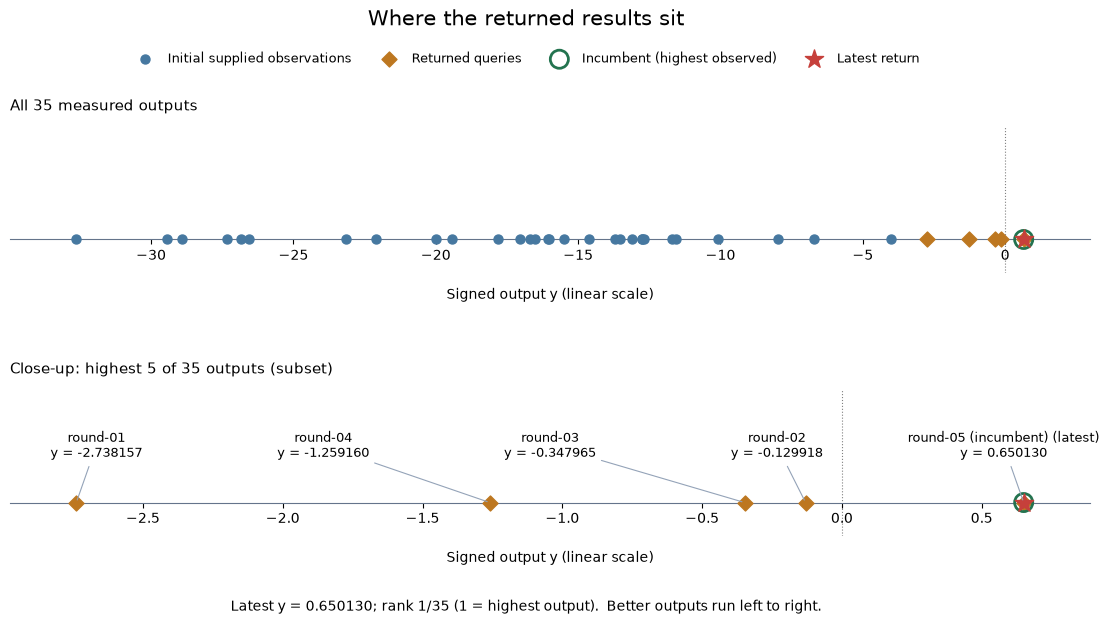

In [4]:
plot_output_review(review, save_to=FIGURES_DIR / "observed-output-review.png")

### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [5]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(precision=6, na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,-4.025542,Not applicable
Round 1,-2.738157,-2.738157,1.287385
Round 2,-0.129918,-0.129918,2.608239
Round 3,-0.347965,-0.129918,-0.218047
Round 4,-1.259160,-0.129918,-1.129242
Round 5,0.650130,0.650130,0.780049


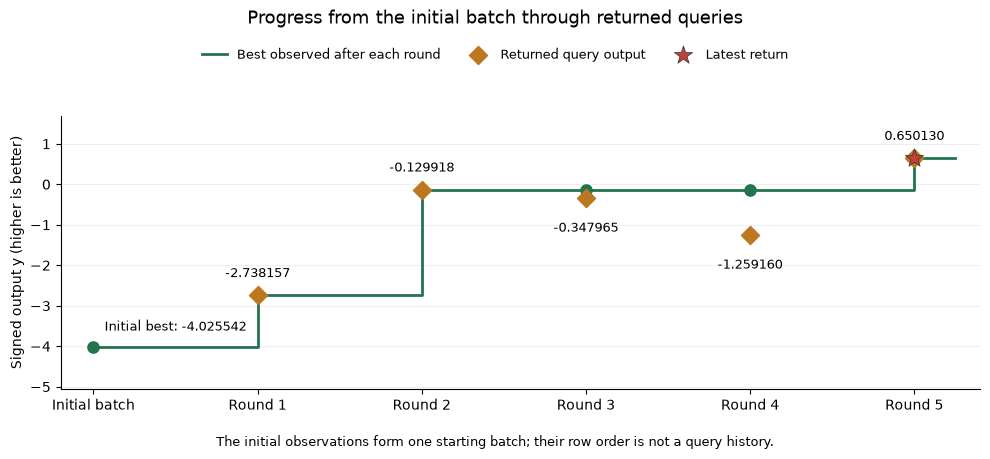

In [6]:
plot_round_progress(prepared["progress"], save_to=FIGURES_DIR / "observed-progress.png")

### Strongest measured input combinations

Keep all 4 coordinates visible. Colour shows input settings on a common 0–1 scale; it does not encode performance or input effects. Use the table for six-decimal settings.

,rank,source_round,x1,x2,x3,x4,y
observation_id,,,,,,,
round-05,1,5,0.419096,0.406060,0.408855,0.426466,0.650130
round-02,2,2,0.445520,0.390792,0.374106,0.377372,-0.129918
round-03,3,3,0.459127,0.368781,0.430162,0.390645,-0.347965
round-04,4,4,0.354513,0.376712,0.378960,0.488593,-1.259160
round-01,5,1,0.377878,0.477308,0.239218,0.435290,-2.738157


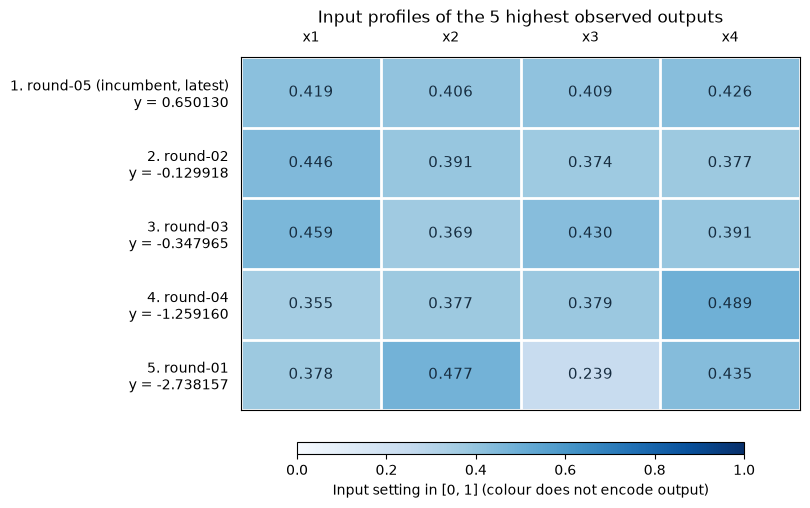

In [7]:
display(prepared["strongest"][["rank", "observation_id", "source_round", *INPUT_COLUMNS, OUTPUT_COLUMN]]
    .set_index("observation_id").style.format({column: "{:.6f}" for column in [*INPUT_COLUMNS, OUTPUT_COLUMN]}))
plot_input_profiles(
    prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=prepared["latest"]["observation_id"], incumbent_id=prepared["incumbent"]["observation_id"],
    save_to=FIGURES_DIR / "strongest-input-profiles.png",
)


### Latest input versus earlier evidence

Distances use every input coordinate. Similar input settings do not guarantee similar outputs or isolate the effect of one coordinate.

In [8]:
display(prepared["coordinate_changes"].style.format(precision=6))
display(pd.Series(prepared["neighbour_summary"]))


,Previous best,Latest query,Latest minus previous best
x1,0.445520,0.419096,-0.026424
x2,0.390792,0.406060,0.015268
x3,0.374106,0.408855,0.034749
x4,0.377372,0.426466,0.049094


previous_best_id              round-02
previous_best_output         -0.129918
distance_to_previous_best     0.067447
latest_minus_previous_best    0.780049
nearest_previous_id           round-02
nearest_previous_distance     0.067447
dtype: object

### Saved Week 5 forecast at the submitted input

Read the preserved submission selection record without refitting. Posterior SD is model dependent; one forecast error does not establish calibration. UCB is a selection score, not a measured return.

In [9]:
# Read the saved selection record at the actual submitted input; no model is refitted.
stage_dir = shared_dir.parent.parent
selection_path = stage_dir / "submissions/Week_05/proposals.json"
if hashlib.sha256(selection_path.read_bytes()).hexdigest() != "6ca900244a2c11ab030075a37c7aae25ef8362651db03ddbc78b7b324cd5bcca":
    raise ValueError("The historical Week 5 selection record has changed.")
selection = next(row for row in json.loads(selection_path.read_text(encoding="utf-8"))["candidates"]
                 if row["function"] == FUNCTION_NUMBER)
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
if not np.array_equal(actual_point, np.asarray(selection["point"], dtype=float)):
    raise ValueError("Saved forecast coordinates do not match the returned query.")
historical_forecast = dict(selection.get("model_prediction") or {})
historical_forecast["data_scope"] = selection["data_scope"]
historical_forecast["actual_output"] = float(prepared["latest"][OUTPUT_COLUMN])
if "predicted_output" in historical_forecast:
    historical_forecast["actual_minus_prediction"] = (
        historical_forecast["actual_output"] - historical_forecast["predicted_output"])
else:
    historical_forecast["forecast_status"] = "Not applicable: fixed coverage selection"
display(pd.Series(historical_forecast))


predicted_output                                                  -0.68957
posterior_std                                                     0.429507
ucb                                                               0.152263
ucb_weight                                                            1.96
inside_sampled_hull                                                   True
data_scope                 official_fit_with_saved_common_candidate_review
actual_output                                                      0.65013
actual_minus_prediction                                             1.3397
dtype: object

### What the return adds

The new return is the first positive official observation and improves the incumbent. Its output exceeds the saved GP mean at these exact coordinates. The query was selected under the official fit using the saved common candidate pool; the initial provisional notebook proposal was different. Preserve this new incumbent when reviewing local refinement and uncertainty. A single successful return does not establish a maximum or calibrated uncertainty.

In [10]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
print(json.dumps(observation_summary, indent=2))


{
  "function": 4,
  "week": 6,
  "observations": 35,
  "latest_id": "round-05",
  "latest_output": 0.6501304054949952,
  "latest_rank": 1,
  "rank_definition": "1 = highest output",
  "best_id": "round-05",
  "best_observed_output": 0.6501304054949952,
  "positive_outputs": 1,
  "negative_outputs": 34,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": -4.025542281908162,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -2.738157434185442,
      "best_y": -2.738157434185442,
      "change_vs_prior_best": 1.2873848477227203
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -0.12991814521724931,
      "best_y": -0.12991814521724931,
      "change_vs_prior_best": 2.6082392889681927
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      "returned_y": -0.347965

### Course lifecycle for this review

1. **Define the goal and scope** — review round 5 for the project owner and prepare evidence for the Week 6 decision; success means a reconciled return and an accurate descriptive review.
2. **Gather the data** — use the retained 30 October results email, original cumulative attachments and independent official CSV snapshot.
3. **Explore the data** — inspect measured ranks, progress and coverage or full input profiles.
4. **Clean and preprocess the data** — validate dimensions, bounds, finite values and round counts; preserve all rows and full float64 precision.
5. **Select and engineer features** — retain the existing ordered input coordinates; no engineered features are required.
6. **Define the machine-learning task** — continuous black-box maximisation remains the task; this notebook provides descriptive evidence.
7. **Partition the data** — not applicable: no new model is fitted or validated in this observation review.
8. **Select and train candidate methods** — not applicable: any Week 6 model comparison is separate work.
9. **Evaluate and interpret the results** — compare the measured return with earlier outputs, the prior incumbent and the saved forecast where one informed selection.
10. **Deploy and iterate** — no deployment applies; carry this evidence into the next query review. Eight query opportunities remain, including Week 6; this notebook submits no query.
